# Neural architecture validation

This is an interface-validation report, not a model-selection benchmark.
Small training budgets exercise public methods across the registry. Metrics
are labeled by task and evaluation split; poor scores are not teaching targets.
For fitted teaching examples, use the [tutorials](../../tutorials/index.rst).


**Execution environment:** nampy 0.3.0, numpy 1.26.4, scikit-learn 1.9.0, torch 2.14.1+cpu, lightning 2.6.6. Python 3.12.13; source base commit `4cffdeb` (working checkout); elapsed 18.9 seconds on this CPU. Runtime varies by hardware.

## 1. A common neural workflow

PreTab transforms numerical and categorical inputs while retaining
source-feature groups. Early stopping monitors validation loss;
learning-rate schedules change the optimization trajectory; checkpoint
averaging averages recent model states. Sample weights alter the empirical loss.

For the additive structure and centering conventions, see
[Additive predictors and identifiability](../../concepts/additive_predictors.rst).
Explicit interactions should be chosen from domain knowledge or a discovery
procedure evaluated separately from final fitting.

For main effects the neural predictor is
$\eta(x)=\beta_0+\sum_j f_j(x_j;w_j)$. An interaction network instead
receives a selected subset of features jointly. Training minimizes a task
loss, such as squared error or negative log likelihood, plus any configured
regularization. Additivity concerns how outputs combine; it does not require
the feature functions themselves to be linear. The following examples change
the function class while keeping the prediction and component interfaces.


In [1]:
from pathlib import Path
import tempfile
import time
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
logging.getLogger("lightning.pytorch").setLevel(logging.ERROR)
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = ["#2563EB", "#F97316", "#10B981", "#8B5CF6", "#EF4444"]

N_SAMPLES = 1000
MAX_EPOCHS = 20
RANDOM_STATE = 7
CHECKPOINT_ROOT = Path(tempfile.mkdtemp(prefix="nampy-notebook-"))

NEURAL_FIT_KWARGS = {
    "max_epochs": MAX_EPOCHS,
    "batch_size": 256,
    "random_state": RANDOM_STATE,
    "checkpoint_path": CHECKPOINT_ROOT,
    "logger": False,
    "enable_progress_bar": False,
    "enable_model_summary": False,
    "num_sanity_val_steps": 0,
}

rng = np.random.default_rng(RANDOM_STATE)

n = N_SAMPLES
x1 = rng.uniform(-1.0, 1.0, n)
x2 = rng.normal(size=n)
group = pd.Categorical(rng.choice(["a", "b", "c"], size=n))
X = pd.DataFrame({"x1": x1, "x2": x2, "group": group})
y = np.sin(np.pi * x1) + 0.35 * x2**2 + 0.45 * x1 * x2 + 0.25 * (group == "b") + rng.normal(0, 0.15, n)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

from nampy import models

ARCH_KWARGS = {
    "linreg": {},
    "nam": {"layer_sizes": [12], "dropout": 0.0, "interactions": [("x1", "x2")]},
    "sian": {"layer_sizes": [12], "interactions": [("x1", "x2")]},
    "snam": {"layer_sizes": [12], "dropout": 0.0, "group_lasso_lambda": 0.01},
    "gpnam": {"rff_num_feat": 12, "interactions": [("x1", "x2")]},
    "igann": {"n_hid": 6, "n_estimators": 4, "early_stopping": 2},
    "nbm": {"layer_sizes": [12], "num_bases": 6, "nary": [1, 2], "dropout": 0.0, "bases_dropout": 0.0},
    "nbm_spam": {"layer_sizes": [12], "num_bases": 6, "ranks": [6], "batch_norm": False},
    "spam": {"ranks": [6], "dropout": 0.0},
    "natt": {"d_model": 8, "n_layers": 1, "n_heads": 2, "transformer_dim_feedforward": 16, "head_layer_sizes": (), "attn_dropout": 0.0},
    "namformer": {"d_model": 8, "n_layers": 1, "n_heads": 2, "transformer_dim_feedforward": 16, "head_layer_sizes": (), "attn_dropout": 0.0},
    "treenam": {"tree_depth": 2, "tree_lamda": 0.01},
    "ensemble_treenam": {"tree_depth": 2, "tree_lamda": 0.01, "num_estimators": 2},
    "nodegam": {"num_trees": 4, "num_layers": 1, "depth": 2, "anneal_steps": 10, "interaction_degree": 1},
    "qnam": {"layer_sizes": [12], "dropout": 0.0, "distributional_kwargs": {"quantiles": [0.1, 0.5, 0.9]}},
    "spline_nam": {"n_knots": 6, "smoothing": 0.01, "interactions": [("x1", "x2")]},
}

fitted_gallery = {}
comparison_rows = []

def parameter_count(estimator):
    module = getattr(getattr(estimator, "model", None), "model", None)
    return None if module is None else sum(p.numel() for p in module.parameters())

def reconstruct_components(components):
    link = np.asarray(components.link)
    def aligned(value):
        array = np.asarray(value, dtype=float)
        if link.ndim == 1 and array.shape == (link.shape[0], 1):
            return array[:, 0]
        if link.ndim == 2 and array.shape == (link.shape[0],):
            return array[:, None]
        return array
    reconstruction = aligned(components.intercept)
    for contribution in components.terms.values():
        reconstruction = reconstruction + aligned(contribution)
    if components.offset is not None:
        reconstruction = reconstruction + aligned(components.offset)
    return reconstruction

def fit_and_evaluate(name, estimator, target=y_train):
    started = time.perf_counter()
    estimator.fit(X_train, target, **NEURAL_FIT_KWARGS)
    elapsed = time.perf_counter() - started
    components = estimator.predict_components(X_test, center=True)
    reconstruction = reconstruct_components(components)
    error = float(np.max(np.abs(reconstruction - components.link)))
    reconstruction_valid = error <= 1e-5
    assert reconstruction_valid, (name, error)
    row = {
        "model": name,
        "metric": "negative pinball loss" if "QNAM" in name else "R2",
        "test score": estimator.score(X_test, y_test),
        "fit seconds": elapsed,
        "terms": len(components.terms),
        "interactions": len(estimator.interaction_importance(X_test, center=True)),
        "parameters": parameter_count(estimator),
        "reconstruction error": error,
        "reconstruction valid": reconstruction_valid,
    }
    fitted_gallery[name] = estimator
    comparison_rows.append(row)
    return row

def architecture_summary(estimator):
    return {
        "class": type(estimator).__name__,
        "architecture": estimator.architecture_name,
        "parameters": parameter_count(estimator),
        "features": estimator.feature_names_in_.tolist(),
    }


### 1.1 Preprocessing, training, and explanation with NAM

Min-max scaling maps numerical columns to a bounded range. PLE creates
piecewise-linear encodings with several transformed columns per source
feature. One-hot encoding keeps a categorical source feature grouped even
though it expands into multiple columns. Scaling and encoding are fitted
on training data only.


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'class': 'NAMRegressor',
 'architecture': 'nam',
 'parameters': 1517,
 'features': ['x1', 'x2', 'group']}

,term,term_type,output,importance
0,group,main,0,0.031500
1,x1:x2,interaction,0,0.018951
2,x1,main,0,0.006899
3,x2,main,0,0.000643


,term,term_type,output,value,value_2,contribution,count,importance
0,x1,main,0,-0.9405,NaN,0.015479,14,0.006899
1,x1,main,0,-0.8485,NaN,0.013491,14,0.006899
2,x1,main,0,-0.7615,NaN,0.011044,14,0.006899
3,x1,main,0,-0.668,NaN,0.008737,14,0.006899
4,x1,main,0,-0.566,NaN,0.006482,14,0.006899
5,x1,main,0,-0.455,NaN,0.003348,14,0.006899
6,x1,main,0,-0.3235,NaN,0.001355,13,0.006899
7,x1,main,0,-0.1805,NaN,0.000838,14,0.006899
8,x1,main,0,-0.0842,NaN,0.000545,14,0.006899
9,x1,main,0,-0.00745,NaN,0.000308,14,0.006899


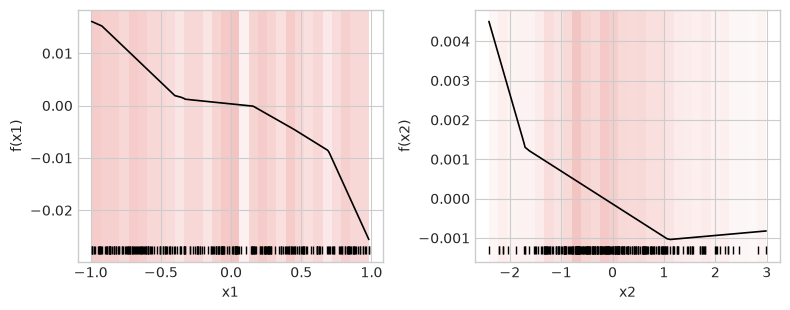

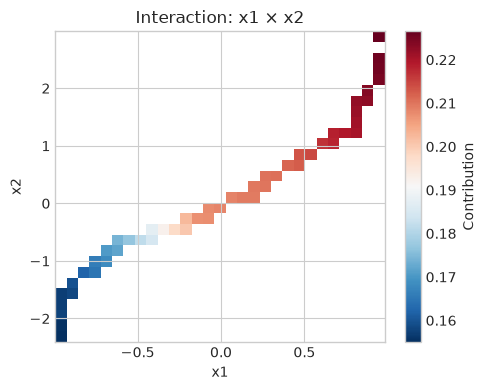

In [2]:
from nampy.models import NAMRegressor

nam = NAMRegressor(
    layer_sizes=[24, 12], dropout=0.0,
    numerical_preprocessing="minmax",
    categorical_preprocessing="one-hot",
    interactions=[("x1", "x2")],
)
fit_and_evaluate("NAM", nam)

components = nam.predict_components(X_test, center=True)
display(architecture_summary(nam))
display(nam.term_importance(X_test, center=True))
display(nam.explain_terms(X_test, max_bins=18, center=True).head(12))
nam.plot_terms(X_test, center=True, rug=True, pages=1)
nam.plot_interactions(X_test)


## 2. Available architectures

The installed registry is the source of truth. It records task support
and architectural contracts without claiming that every combination is
equally useful. In particular, QNAM is distributional-only and
SplineNAM is regression-only; IGANN does not advertise interactions.


In [3]:
from nampy.neural.registry import architectures

capability_rows = []
for name, spec in architectures().items():
    capability_rows.append({
        "architecture": name,
        "Regressor": spec.supports("regression"),
        "Classifier": spec.supports("classification"),
        "LSS": spec.supports("distributional"),
        "interactions": spec.supports("interactions"),
        "interaction discovery": spec.supports("interaction_selection"),
        "local importance": spec.supports("local_term_importance"),
        "native solver": spec.supports("native_training"),
    })
capability_table = pd.DataFrame(capability_rows)
capability_table


,architecture,Regressor,Classifier,LSS,interactions,interaction discovery,local importance,native solver
0,linreg,True,True,True,False,False,False,False
1,nam,True,True,True,True,False,False,False
2,sian,True,True,True,True,True,False,False
3,snam,True,True,True,True,False,False,False
4,gpnam,True,True,True,True,False,False,False
5,igann,True,True,True,False,False,False,True
6,nbm,True,True,True,True,False,False,False
7,nbm_spam,True,True,True,True,False,False,False
8,spam,True,True,True,True,False,True,False
9,natt,True,True,True,True,False,False,False


## 3. Linear baseline: LinReg

LinReg preserves the additive contract while restricting every numerical
effect to a line and categorical effects to learned level shifts. It is a
useful sanity check: nonlinear models should justify their added
flexibility against this baseline.

For a numerical feature, LinReg uses $f_j(x_j)=w_jx_j$. The constant slope
means that equal feature increments have equal predictor-scale effects.
Compare its held-out score with the nonlinear fits, then inspect whether
curved effects explain the difference. A more flexible model is useful only
if its extra structure generalizes.


In [4]:
from nampy.models import LinRegRegressor
linreg = LinRegRegressor(numerical_preprocessing="standardization")
display(fit_and_evaluate("LinReg", linreg))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'LinReg',
 'metric': 'R2',
 'test score': -4.8737966851610794,
 'fit seconds': 0.6241825170000084,
 'terms': 3,
 'interactions': 0,
 'parameters': 7,
 'reconstruction error': 1.83936208486557e-07,
 'reconstruction valid': True}

## 4. Feature networks: NAM

NAM assigns one multilayer perceptron to each source feature and optional
networks to explicit interactions. Width, feature-layer type, dropout,
normalization, and regularization control complexity. Centering produces
stable shape functions but does not make observational effects causal.

A feature network composes affine maps and nonlinear activations, for
example $f_j(x)=a_j^\top\phi(W_jx+b_j)$. It can represent changing slopes
without imposing a spline basis. The resulting shape plot shows the network
output over observed feature values; sparse regions are weakly informed even
when the curve looks smooth. Check the plotted density before interpreting
behavior near the extremes.


In [5]:
display({key: nam.get_params(deep=False)[key] for key in ("layer_sizes", "dropout", "interactions")})


{'layer_sizes': [24, 12], 'dropout': 0.0, 'interactions': [('x1', 'x2')]}

## 5. Interaction discovery: SIAN

SIAN can fit a reference network, score candidate interactions with an
Archipelago-style detector, enforce hierarchy, and then fit selected
higher-order terms. Explicit interactions bypass discovery. Compression
changes execution layout after fitting while preserving predictions.

A pure main-effect model assumes one feature's contribution is independent
of the others. A term $f_{jk}(x_j,x_k)$ relaxes that assumption. Interaction
discovery searches for useful joint terms before the final additive fit.
A detector score ranks candidates; it is not a hypothesis-test p-value.
Inspect a selected surface and evaluate held-out performance to decide
whether the added structure is useful.


In [6]:
from nampy.models import SIANRegressor
sian = SIANRegressor(layer_sizes=[12], interactions=[("x1", "x2")])
display(fit_and_evaluate("SIAN", sian))
before = sian.predict(X_test)
sian.compress_terms()
compression_difference = float(np.max(np.abs(before - sian.predict(X_test))))
display({"maximum prediction change after compression": compression_difference})
sian.block_mask_terms()


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'SIAN',
 'metric': 'R2',
 'test score': 0.32512243941995655,
 'fit seconds': 0.5171473139926093,
 'terms': 4,
 'interactions': 1,
 'parameters': 485,
 'reconstruction error': 9.068753570318222e-08,
 'reconstruction valid': True}

{'maximum prediction change after compression': 1.1920928955078125e-07}

,activation,<class 'torch...ivation.ReLU'>
,archipelago_baseline,'pairwise'
,dropout,0.0
,execution_mode,'block_masked'
,feature_output_bias,True
,heredity_fraction,0.5
,interaction_degree,None
,interaction_detector,'archipelago'
,interaction_thresholds,0.1
,interactions,"[('x1', ...)]"
,intercept,True


## 6. Group sparsity: SNAM

SNAM adds a group-lasso penalty over feature and optionally interaction
subnetworks. Whole terms can be driven toward zero. Inspect group norms
across a regularization path; a larger penalty favors a smaller model but
can underfit weak real effects.

A schematic group penalty is $\lambda\sum_j\|w_j\|_2$, where a group
contains parameters belonging to one term. Unlike independent weight decay,
it encourages entire parameter groups to vanish. In the group-norm output,
a small norm indicates strong shrinkage, while the effect plot shows how
much contribution remains on the prediction scale. Correlated features can
substitute for one another, so sparsity is not proof of unique relevance.


In [7]:
from nampy.models import SNAMRegressor
snam = SNAMRegressor(layer_sizes=[12], dropout=0.0, group_lasso_lambda=0.02)
display(fit_and_evaluate("SNAM", snam))
display(snam.group_norms())
display(snam.model.model.selected_groups(threshold=1e-6))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'SNAM',
 'metric': 'R2',
 'test score': -0.5627082160201957,
 'fit seconds': 0.5728219150041696,
 'terms': 3,
 'interactions': 0,
 'parameters': 568,
 'reconstruction error': 5.820766091346741e-08,
 'reconstruction valid': True}

{'x1': 2.0205485820770264,
 'x2': 2.1690292358398438,
 'group': 2.986497163772583}

['x1', 'x2', 'group']

## 7. Random Fourier features: GPNAM

GPNAM approximates stationary Gaussian-process kernels with random Fourier
features, then solves a regularized linear problem. Kernel widths govern
smoothness; the feature count governs approximation fidelity. Pairwise
RFF blocks provide GP-NA2M-style interactions.

Random Fourier features map an input to oscillating features such as
$\phi_r(x)=\sqrt{2/m}\cos(\omega_rx+b_r)$ and fit their coefficients with
regularization. For suitable sampled frequencies their inner products
approximate a stationary kernel. Kernel width sets the characteristic scale
of variation; the number of features controls the approximation. Read the
learned curve as a regularized finite-feature fit rather than an exact
Gaussian-process posterior.


In [8]:
from nampy.models import GPNAMRegressor
gpnam = GPNAMRegressor(rff_num_feat=12, interactions=[("x1", "x2")])
display(fit_and_evaluate("GPNAM", gpnam))
display(gpnam.model.model.basis_metadata())


{'model': 'GPNAM',
 'metric': 'R2',
 'test score': 0.45875205119442497,
 'fit seconds': 0.04639140200742986,
 'terms': 6,
 'interactions': 1,
 'parameters': 73,
 'reconstruction error': 2.505257725715637e-07,
 'reconstruction valid': True}

{'feature_names': ('x1', 'x2', 'group[0]', 'group[1]', 'group[2]'),
 'interaction_names': ('x1:x2',),
 'kernel_widths': array([0.02407884, 0.04237896, 0.01980659, 0.01920233, 0.01989572],
       dtype=float32),
 'frequencies': array([-1.4260769 , -1.0200763 , -0.73631597, -0.5024022 , -0.2933812 ,
        -0.09655861,  0.09655868,  0.29338127,  0.50240225,  0.73631597,
         1.0200763 ,  1.4260769 ], dtype=float32),
 'phases': array([[1.5707964, 2.0943952, 0.       , 2.617994 , 3.6651917, 4.712389 ,
         5.759587 , 3.1415927, 4.1887903, 0.5235988, 5.235988 , 1.0471976],
        [3.6651917, 3.1415927, 4.712389 , 2.617994 , 0.5235988, 1.5707964,
         5.235988 , 2.0943952, 0.       , 1.0471976, 4.1887903, 5.759587 ],
        [5.759587 , 4.1887903, 5.235988 , 2.617994 , 3.6651917, 0.5235988,
         3.1415927, 1.0471976, 0.       , 2.0943952, 4.712389 , 1.5707964],
        [3.6651917, 0.       , 4.1887903, 1.5707964, 5.759587 , 2.0943952,
         1.0471976, 2.617994 , 4.712389

## 8. ELM boosting: IGANN

IGANN begins with a linear fit and sequentially adds feature-wise extreme
learning machine stages with fixed random hidden weights. Regression and
binary classification use its native boosting solver. Interactions are
not advertised by the registry.

Boosting builds an additive predictor in stages:
$\eta^{(t)}(x)=\eta^{(t-1)}(x)+\nu h_t(x)$. The next stage targets what the
current model has not explained, and the learning rate $\nu$ limits each
update. Fixed random hidden features make fitting each stage different from
backpropagating through every hidden weight. Validation behavior helps choose
when additional stages stop improving generalization.


In [9]:
from nampy.models import IGANNRegressor
igann = IGANNRegressor(n_hid=6, n_estimators=4, early_stopping=2)
display(fit_and_evaluate("IGANN", igann))
display(igann.training_history_)


{'model': 'IGANN',
 'metric': 'R2',
 'test score': 0.5608361517657919,
 'fit seconds': 0.03668260099948384,
 'terms': 3,
 'interactions': 0,
 'parameters': 61,
 'reconstruction error': 1.7881393432617188e-07,
 'reconstruction valid': True}

{'train_loss': (0.40243983268737793,
  0.38003626465797424,
  0.3744937479496002,
  0.37389856576919556),
 'val_loss': (0.352098286151886,
  0.3369818329811096,
  0.3320246636867523,
  0.33220773935317993)}

## 9. Shared learned bases: NBM

NBM learns reusable unary bases and composes them into n-ary subnetworks.
Dense mode evaluates configured orders; sparse mode can ignore inactive
inputs. Shared bases reduce duplicated representation learning and make
higher-order structure explicit.

Sharing a library of learned basis functions lets multiple terms reuse
nonlinear building blocks instead of learning each representation entirely
from scratch. Main-effect and higher-order outputs are still separate
additive terms. Compare their extracted contributions with the NAM curves:
sharing changes the representation and regularization, while the response
and contribution scales remain comparable.


In [10]:
from nampy.models import NBMRegressor
nbm = NBMRegressor(layer_sizes=[12], num_bases=6, nary=[1, 2], dropout=0.0, bases_dropout=0.0)
display(fit_and_evaluate("NBM", nbm))
display({"orders": nbm.get_params(deep=False)["nary"], "featurizer": nbm.get_params(deep=False)["featurizer"]})


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'NBM',
 'metric': 'R2',
 'test score': -0.3500786440502892,
 'fit seconds': 0.7827283209917368,
 'terms': 15,
 'interactions': 1,
 'parameters': 409,
 'reconstruction error': 1.138541848022534e-07,
 'reconstruction valid': True}

{'orders': [1, 2], 'featurizer': 'conv1d'}

## 10. Polynomial structure and local importance: SPAM

SPAM represents low-rank polynomial interactions. `ranks` configures the polynomial heads and their factorization widths;
`reg_order` controls the norm used for regularization, not polynomial degree. Because polynomial
terms can be evaluated row by row, SPAM exposes local term importance in
addition to global mean-absolute contribution.

Low-rank factorization represents a large collection of polynomial
interactions using products of lower-dimensional projections. Degree controls
which orders can occur; rank controls representational capacity within those
orders. Local importance varies with the evaluated row, whereas global
importance averages contribution magnitude across rows. A feature can
therefore matter strongly for a few observations without ranking highly on
average.


In [11]:
from nampy.models import SPAMRegressor
spam = SPAMRegressor(ranks=[6], reg_order=2, regularization_scale=1e-5)
display(fit_and_evaluate("SPAM", spam))
display(spam.local_term_importance(X_test.iloc[:3], top_k=4))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'SPAM',
 'metric': 'R2',
 'test score': 0.05551093841525323,
 'fit seconds': 0.519172514003003,
 'terms': 6,
 'interactions': 0,
 'parameters': 42,
 'reconstruction error': 3.725290304013029e-08,
 'reconstruction valid': True}

[[{'term': ('x1',), 'order': 1, 'contribution': 0.21948029100894928},
  {'term': ('group[1]',), 'order': 1, 'contribution': 0.11830691248178482},
  {'term': ('x1', 'group[1]'),
   'order': 2,
   'contribution': 0.013601006008684635},
  {'term': ('x2',), 'order': 1, 'contribution': 0.0028191778110340238}],
 [{'term': ('x1',), 'order': 1, 'contribution': 0.20878258161246777},
  {'term': ('group[1]',), 'order': 1, 'contribution': 0.11830691248178482},
  {'term': ('x2',), 'order': 1, 'contribution': 0.03247865196317434},
  {'term': ('x1', 'group[1]'),
   'order': 2,
   'contribution': 0.013265402056276798}],
 [{'term': ('x1',), 'order': 1, 'contribution': -0.18620585463941097},
  {'term': ('group[1]',), 'order': 1, 'contribution': 0.11830691248178482},
  {'term': ('x1', 'group[1]'),
   'order': 2,
   'contribution': -0.011570941656827927},
  {'term': ('x1', 'x2'), 'order': 2, 'contribution': 0.007149345241487026}]]

## 11. Shared bases with polynomial heads: NBM-SPAM

NBM-SPAM feeds NBM's shared learned unary bases into SPAM-style low-rank
polynomial heads. Relative to NBM it makes the interaction algebra more
explicit; relative to SPAM it learns a richer common representation.

The learned unary representation transforms each feature before polynomial
heads combine those representations. Nonlinearity can therefore arise both
within a feature and through cross-feature products. Interpret the extracted
named terms at the source-feature level; individual shared basis coordinates
need not have a unique interpretation.


In [12]:
from nampy.models import NBMSPAMRegressor
nbm_spam = NBMSPAMRegressor(layer_sizes=[12], num_bases=6, ranks=[6], batch_norm=False)
display(fit_and_evaluate("NBM-SPAM", nbm_spam))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'NBM-SPAM',
 'metric': 'R2',
 'test score': 0.024347737889538146,
 'fit seconds': 0.6237910159979947,
 'terms': 6,
 'interactions': 0,
 'parameters': 317,
 'reconstruction error': 3.539025772436588e-08,
 'reconstruction valid': True}

## 12. Additive attention: NATT

NATT uses attention inside additive feature representations and extracts
named term effects from the model output. Attention weights describe an
internal routing mechanism; they are not causal effects and should not be
substituted for component reconstruction or perturbation analysis.

Attention typically forms weights
$A=\operatorname{softmax}(QK^\top/\sqrt d)$ and aggregates value vectors
through $AV$. This describes internal information routing. The explanatory
quantity in an additive estimator is the extracted term output, whose units
match the predictor. A large attention weight alone does not establish a
large contribution to the final prediction.


In [13]:
from nampy.models import NATTRegressor
natt = NATTRegressor(d_model=8, n_layers=1, n_heads=2, transformer_dim_feedforward=16, head_layer_sizes=(), attn_dropout=0.0)
display(fit_and_evaluate("NATT", natt))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'NATT',
 'metric': 'R2',
 'test score': 0.26808210799377474,
 'fit seconds': 1.0609564280021004,
 'terms': 3,
 'interactions': 0,
 'parameters': 48220,
 'reconstruction error': 5.797483026981354e-08,
 'reconstruction valid': True}

## 13. Identifiable transformer effects: NAMformer

NAMformer uses a transformer backbone while retaining explicit marginal
outputs. The additive reconstruction is the operational identifiability
check. Effect stability should also be assessed across seeds and data
splits because a valid decomposition need not be statistically stable.

A transformer representation can use context from several inputs. That
makes the distinction between reconstructing a prediction and identifying
a marginal effect especially important. Summing reported terms checks
accounting; checking how each term changes under input perturbations probes
its feature dependence. Use these checks and repeated fits before treating
a stable-looking shape as a uniquely identified relationship.


In [14]:
from nampy.models import NAMformerRegressor
namformer = NAMformerRegressor(d_model=8, n_layers=1, n_heads=2, transformer_dim_feedforward=16, head_layer_sizes=(), attn_dropout=0.0)
display(fit_and_evaluate("NAMformer", namformer))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'NAMformer',
 'metric': 'R2',
 'test score': -0.41022977799472193,
 'fit seconds': 0.7627026199916145,
 'terms': 4,
 'interactions': 0,
 'parameters': 1013,
 'reconstruction error': 1.5599653124809265e-07,
 'reconstruction valid': True}

## 14. One differentiable tree per term: TreeNAM

TreeNAM uses soft decision trees for main and interaction terms. Its
shapes are piecewise rather than globally smooth. Depth increases the
number of regions and therefore the risk of fitting small-sample noise.

A differentiable tree replaces a hard branch with a soft gate, for example
$q(x)=\operatorname{sigmoid}\{a(x_j-t)\}$. Leaf values are combined using
products of gate probabilities along paths. Greater depth permits more
localized changes, while soft gates can make boundaries gradual. A sharp
change in a plotted effect therefore reflects a learned partition rather
than a spline knot.


In [15]:
from nampy.models import TreeNAMRegressor
treenam = TreeNAMRegressor(tree_depth=2, tree_lamda=0.01)
display(fit_and_evaluate("TreeNAM", treenam))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'TreeNAM',
 'metric': 'R2',
 'test score': -0.7918450083677497,
 'fit seconds': 0.6627398179989541,
 'terms': 3,
 'interactions': 0,
 'parameters': 145,
 'reconstruction error': 6.332993507385254e-08,
 'reconstruction valid': True}

## 15. Joint tree ensembles: EnsembleTreeNAM

EnsembleTreeNAM is an architecture that trains several TreeNAM members
jointly and averages their term outputs. It differs from
`NeuralEnsemble`, which clones and independently fits any supported base
regressor or classifier.

For $M$ jointly trained additive trees, an averaged term has the form
$\bar f_j(x_j)=M^{-1}\sum_m f_{mj}(x_j)$. Several members can share the work
of representing one effect. Their joint training means member diversity is
not equivalent to bootstrap variation among independently fitted models;
member spread should not automatically be read as a confidence interval.


In [16]:
from nampy.models import EnsembleTreeNAMRegressor
ensemble_treenam = EnsembleTreeNAMRegressor(tree_depth=2, tree_lamda=0.01, num_estimators=2)
display(fit_and_evaluate("EnsembleTreeNAM", ensemble_treenam))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'EnsembleTreeNAM',
 'metric': 'R2',
 'test score': -0.9670849885940862,
 'fit seconds': 0.7713691200042376,
 'terms': 3,
 'interactions': 0,
 'parameters': 290,
 'reconstruction error': 8.568167686462402e-08,
 'reconstruction valid': True}

## 16. Oblivious additive trees: NodeGAM

NodeGAM stacks differentiable oblivious trees: all nodes at a depth share
a split choice. Feature selection temperature is annealed during
training. Masked pretraining is available for larger runs; extracted
additive terms remain the explanation interface.

An oblivious tree uses the same feature-and-threshold choice at every node
of a given depth. This restricts the partition and makes its computation
regular. Soft feature selection becomes more concentrated as its temperature
is annealed. Inspect the final extracted effect and prediction quality,
rather than assuming that a low selection temperature alone gives a reliable
explanation.


In [17]:
from nampy.models import NodeGAMRegressor
nodegam = NodeGAMRegressor(num_trees=4, num_layers=1, depth=2, anneal_steps=10, interaction_degree=1)
display(fit_and_evaluate("NodeGAM", nodegam))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'NodeGAM',
 'metric': 'R2',
 'test score': -0.36336427035917773,
 'fit seconds': 0.6826027179922676,
 'terms': 3,
 'interactions': 0,
 'parameters': 383,
 'reconstruction error': 9.313225746154785e-08,
 'reconstruction valid': True}

## 17. Non-crossing conditional quantiles: QNAM

QNAM predicts several conditional quantiles under pinball loss. A
monotone transform parameterizes successive quantile increments, making
non-crossing structural rather than a post-hoc sort. The gap between two
quantiles forms a conditional prediction interval.

The conditional $\tau$-quantile minimizes expected pinball loss,

$$\rho_\tau(u)=u\{\tau-\mathbf{1}(u<0)\},\qquad u=y-q_\tau(x).$$

Underprediction and overprediction receive different weights. A central
interval $[q_{0.1}(x),q_{0.9}(x)]$ targets 80% conditional coverage when the
quantiles are calibrated. Ordered outputs prevent crossing, but do not by
themselves guarantee that coverage. Inspect both ordering and held-out
interval behavior.


In [18]:
from nampy.models import QNAMLSS
qnam = QNAMLSS(layer_sizes=[12], dropout=0.0, distributional_kwargs={"quantiles": [0.1, 0.5, 0.9]})
display(fit_and_evaluate("QNAM", qnam))
predicted_quantiles = qnam.predict(X_test)
minimum_gap = float(np.diff(predicted_quantiles, axis=1).min())
display({"minimum adjacent quantile gap": minimum_gap})


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'QNAM',
 'metric': 'negative pinball loss',
 'test score': -2.3104708194732666,
 'fit seconds': 0.6312428169912891,
 'terms': 3,
 'interactions': 0,
 'parameters': 648,
 'reconstruction error': 4.172325134277344e-07,
 'reconstruction valid': True}

{'minimum adjacent quantile gap': 2.4456844329833984}

## 18. Cubic spline layers: SplineNAM

SplineNAM replaces generic feature networks with cubic spline layers.
Knot count determines capacity; a smoothing penalty discourages rough
coefficients. Interaction spline layers extend the same idea to named
feature pairs. Derivative plots reveal how the penalty changes local
slopes.

A spline layer writes a feature function as
$f_j(x)=\sum_r c_{jr}B_r(x)$. Knots determine where local basis functions
can change shape; a roughness penalty discourages unstable coefficient
patterns. Derivative curves show the resulting rates of change. Compare
capacity and penalization separately: more knots need not imply a rougher
fitted function when the penalty is strong.


In [19]:
from nampy.models import SplineNAMRegressor
spline_nam = SplineNAMRegressor(n_knots=6, smoothing=0.01, interactions=[("x1", "x2")])
display(fit_and_evaluate("SplineNAM", spline_nam))


GPU available: False, used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=20` reached.


{'model': 'SplineNAM',
 'metric': 'R2',
 'test score': -0.5333259987049668,
 'fit seconds': 3.658202897000592,
 'terms': 4,
 'interactions': 1,
 'parameters': 29,
 'reconstruction error': 7.450580596923828e-08,
 'reconstruction valid': True}

## 19. Compare fitted models

The table uses one split, a common training budget, and each architecture's
required preprocessing. It is an interface and scale
check—not a competitive benchmark. Serious comparisons need tuned
budgets, repeated splits, uncertainty, and task-appropriate metrics.


In [20]:
comparison = pd.DataFrame(comparison_rows).sort_values(["metric", "model"])
comparison


,model,metric,test score,fit seconds,terms,interactions,parameters,reconstruction error,reconstruction valid
12,EnsembleTreeNAM,R2,-0.967085,0.771369,3,0,290,8.568168e-08,True
4,GPNAM,R2,0.458752,0.046391,6,1,73,2.505258e-07,True
5,IGANN,R2,0.560836,0.036683,3,0,61,1.788139e-07,True
1,LinReg,R2,-4.873797,0.624183,3,0,7,1.839362e-07,True
0,NAM,R2,-0.210627,0.671651,4,1,1517,9.313226e-08,True
10,NAMformer,R2,-0.410230,0.762703,4,0,1013,1.559965e-07,True
9,NATT,R2,0.268082,1.060956,3,0,48220,5.797483e-08,True
6,NBM,R2,-0.350079,0.782728,15,1,409,1.138542e-07,True
8,NBM-SPAM,R2,0.024348,0.623791,6,0,317,3.539026e-08,True
13,NodeGAM,R2,-0.363364,0.682603,3,0,383,9.313226e-08,True


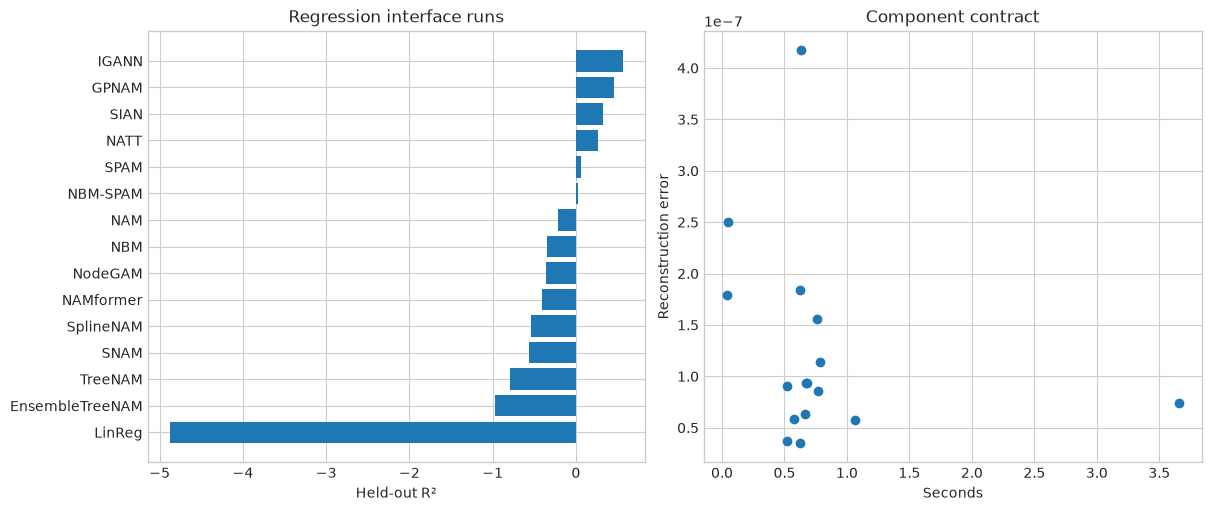

,model,metric,test score
14,QNAM,negative pinball loss,-2.310471


In [21]:
regression = comparison[comparison["metric"] == "R2"].sort_values("test score")
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
axes[0].barh(regression["model"], regression["test score"])
axes[0].set(title="Regression interface runs", xlabel="Held-out R²")
axes[1].scatter(comparison["fit seconds"], comparison["reconstruction error"])
axes[1].set(title="Component contract", xlabel="Seconds", ylabel="Reconstruction error")
plt.show()
plt.close(fig)
display(comparison.loc[comparison["metric"] != "R2", ["model", "metric", "test score"]])
